# Deterministic Taxi Driver: Q-Learning Algorithm

## Setup

In [1]:
import random
from IPython.display import clear_output
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import numpy as np

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1]))

from algorithms.QLearning import QLearning

from numpy import loadtxt
from IPython.display import clear_output
from time import sleep

In [2]:
# environment
env = gym.make("Taxi-v4", render_mode='ansi')

## Train

In [3]:
alpha = 0.5
gamma=0.7
epsilon=0.2
epsilon_min=0.05
epsilon_dec=0.99
episodes=10000

In [4]:
all_rewards = []
q_tables = []

for execution in range(5):
    
    qlearn = QLearning(env, alpha=alpha, gamma=gamma, epsilon=epsilon, epsilon_min=epsilon_min, epsilon_dec=epsilon_dec, episodes=episodes)
    q_table, rewards = qlearn.train("../../data/q-table-deterministic-taxidriver.csv")

    q_tables.append(q_table)
    all_rewards.append(rewards)

    env.close()

## Plot

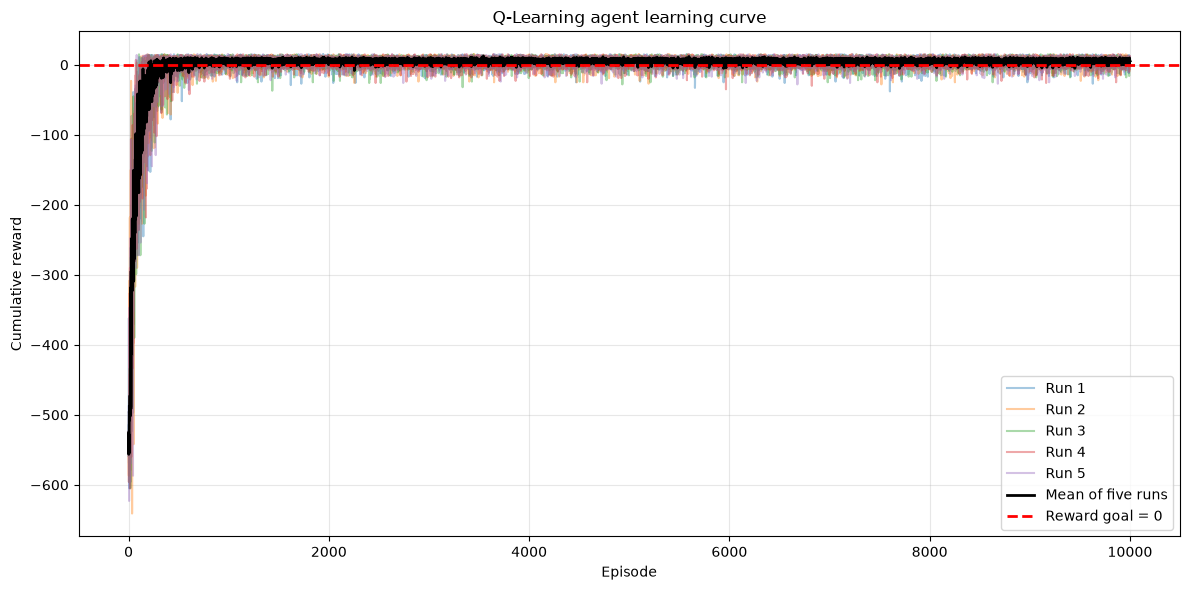

In [5]:
reward_goal = 0
episodes_axis = np.arange(1, episodes + 1)

plt.figure(figsize=(12, 6))

for execution, rewards in enumerate(all_rewards, start=1):
    plt.plot(
        episodes_axis,
        rewards,
        alpha=0.4,
        label=f"Run {execution}"
    )

mean_rewards = np.mean(all_rewards, axis=0)

plt.plot(episodes_axis, mean_rewards, color="black", linewidth=2, label="Mean of five runs")
plt.axhline(y=reward_goal, color="red", linestyle="--", linewidth=2, label=f"Reward goal = {reward_goal}")

plt.xlabel("Episode")
plt.ylabel("Cumulative reward")
plt.title("Q-Learning agent learning curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Test

In [6]:
q_table = loadtxt('../../data/q-table-deterministic-taxidriver.csv', delimiter=',')
env = gym.make("Taxi-v4", render_mode='human')

(state, _) = env.reset()
epochs, penalties, reward = 0, 0, 0
done = False
frames = [] # for animation

while (not done) and (epochs < 100):
    action = np.argmax(q_table[state])
    state, reward, done, t, info = env.step(action)

    if reward == -10:
        penalties += 1

    # Put each rendered frame into dict for animation
    frame = {
        'frame': env.render(),
        'state': state,
        'action': action,
        'reward': reward
        }
    frames.append(frame)
    print(frame)
    epochs += 1

env.close()

{'frame': None, 'state': 173, 'action': np.int64(3), 'reward': -1}
{'frame': None, 'state': 273, 'action': np.int64(0), 'reward': -1}
{'frame': None, 'state': 373, 'action': np.int64(0), 'reward': -1}
{'frame': None, 'state': 473, 'action': np.int64(0), 'reward': -1}
{'frame': None, 'state': 477, 'action': np.int64(4), 'reward': -1}
{'frame': None, 'state': 377, 'action': np.int64(1), 'reward': -1}
{'frame': None, 'state': 397, 'action': np.int64(2), 'reward': -1}
{'frame': None, 'state': 297, 'action': np.int64(1), 'reward': -1}
{'frame': None, 'state': 197, 'action': np.int64(1), 'reward': -1}
{'frame': None, 'state': 97, 'action': np.int64(1), 'reward': -1}
{'frame': None, 'state': 85, 'action': np.int64(5), 'reward': 20}
